# House Prices Valuation - Academic Audit & Consolidated ML Pipeline

## 1. Project Framing & Scope

### A. Business Problem Framing
* **Business Context:** Preliminary house-price estimations are required by a hypothetical real-estate analyst or valuation team to assist in preliminary assessments from observable housing characteristics.
* **Stakeholder:** Real-estate valuation team and analysts.
* **Primary Lens:** Predictive performance, primarily measured by Mean Absolute Error (MAE) in US Dollars ($).
* **Unit of Analysis:** One individual residential property.
* **Target Variable:** `SalePrice` (Continuous USD value).
* **Task:** Supervised Regression.
* **Required Output:** A single predicted sale price per property.
* **Practical Value:** Provides a consistent, repeatable benchmark to support property pricing analysis, comparative market analysis, and preliminary valuation workflows.
* **Boundaries & Limitations:** This model serves as a preliminary evaluation tool. It is not a formal property appraisal and is not guaranteed to generalize to other geographical locations or future markets.

---

### B. Project Workflow Diagram
```
Business Problem → Data Loading → One Development/Holdout Split (Seed 42) → EDA (Dev Only) → Feature Engineering and Preprocessing → Model Comparison Tournament → Hyperparameter Tuning (GridSearchCV) → Untouched Holdout Evaluation → Residual Analysis → Production Refit & Serialization
```

---

### C. Scope and Validation Policy
* **Kaggle Train Dataset (`train.csv`):** Contains the labelled examples used exclusively for developing, cross-validating, and testing our model's performance internally.
* **Kaggle Test Dataset (`test.csv`):** Used solely for generating final unlabelled predictions for submission.
* **Internal Validation Splitting:**
  * **Development Partition (`X_dev`, `y_dev`):** 80% of the training dataset. Used for all exploratory diagnostics, feature-engineering validation, model tournament, and hyperparameter tuning.
  * **Shuffled 5-Fold Cross-Validation:** Applied strictly on the development partition to guide architectural decisions without leakages.
  * **Holdout Partition (`X_holdout`, `y_holdout`):** 20% of the training dataset. Remains completely untouched throughout development and is used strictly once at the end to evaluate generalization performance.

* **Historical Exposure Disclosure:**
  * Earlier notebook versions inspected and reused these labelled observations, including the current holdout. This repair enforces separation in the corrected execution, but it cannot erase that historical exposure. Report the repaired internal holdout result with this limitation; a genuinely fresh external evaluation would require previously unused labelled data.

In [1]:
import os
import sys
import hashlib
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV, learning_curve
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.dummy import DummyRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.feature_selection import SelectFromModel, SelectPercentile, mutual_info_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone

# System reproducible seed
np.random.seed(42)

train_path = '/content/train.csv'
test_path = '/content/test.csv'

if not os.path.exists(train_path) or not os.path.exists(test_path):
    raise FileNotFoundError("Mandatory dataset files train.csv or test.csv could not be found.")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

assert 'SalePrice' in train_df.columns, "Training data is missing target 'SalePrice'"
assert 'Id' in train_df.columns, "Training data is missing 'Id'"
assert 'Id' in test_df.columns, "Test data is missing 'Id'"
assert 'SalePrice' not in test_df.columns, "Test data must not contain 'SalePrice'"

train_cols = set(train_df.columns) - {'SalePrice', 'Id'}
test_cols = set(test_df.columns) - {'Id'}
assert train_cols == test_cols, "Predictor columns do not match between train and test datasets."

target_col_order = list(train_df.drop(columns=['SalePrice', 'Id']).columns)
test_df_aligned = test_df[['Id'] + target_col_order]

y = train_df['SalePrice'].copy()
X = train_df.drop(columns=['SalePrice', 'Id'])
X_test_kaggle = test_df_aligned.drop(columns=['Id'])

# System & Pipeline split setup
X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=42
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
dev_df = train_df.loc[X_dev.index].copy()

assert X_dev.index.intersection(X_holdout.index).empty
assert len(X_dev) + len(X_holdout) == len(X)
assert X_dev.index.equals(y_dev.index)
assert X_holdout.index.equals(y_holdout.index)
assert train_df['Id'].is_unique and test_df['Id'].is_unique
assert np.isfinite(y.to_numpy()).all()

na_meaningful_cols = [
    'Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType'
]

try:
    import xgboost as xgb
    has_xgb = True
except ImportError:
    raise ImportError("XGBoost library is mandatory and must be installed for comparisons.")

holdout_evaluated = False

def get_sha256(filepath):
    sha256_hash = hashlib.sha256()
    with open(filepath, 'rb') as f:
        for byte_block in iter(lambda: f.read(4096), b''):
            sha256_hash.update(byte_block)
    return sha256_hash.hexdigest()

print("=== SYSTEM & PIPELINE PROVENANCE ===")
print(f"Python Version: {sys.version}")
print(f"Scikit-Learn Version: {sklearn.__version__}")
print(f"SHA-256 (train.csv): {get_sha256(train_path)}")
print(f"SHA-256 (test.csv): {get_sha256(test_path)}")
print(f"Development set shape (80%): {X_dev.shape}")
print(f"Holdout set shape (20%): {X_holdout.shape}")

=== SYSTEM & PIPELINE PROVENANCE ===
Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Scikit-Learn Version: 1.6.1
SHA-256 (train.csv): 1e18addf81e5e4d347cc17ee6075bbe4a42b7fa26b9e5b063e8f692a5f929d41
SHA-256 (test.csv): 8fdd3d829d4d986b58f845c9553b225e67dd8383624d90fb6ca1d4bed5798c1e
Development set shape (80%): (1168, 79)
Holdout set shape (20%): (292, 79)


## 2. Programmatic Data Dictionary & Exploratory Data Diagnostics (Development Partition Only)

To ensure complete methodological integrity and prevent any test/holdout contamination, all statistical checks, target distributions, and feature correlations are evaluated strictly on the **Development Partition (`X_dev`, `y_dev`)**.

In [2]:
# Programmatically generate data dictionary statistics on X_dev
missing_counts = X_dev.isnull().sum()
missing_pct = (X_dev.isnull().sum() / len(X_dev)) * 100
cardinality = X_dev.nunique()

columns_list = []
for col in X_dev.columns:
    role = 'Predictor'
    if col == 'MSSubClass':
        strategy = 'Categorical (One-Hot)'
    elif X_dev[col].dtype == 'object':
        if col in na_meaningful_cols:
            strategy = "Constant 'None' Impute (Structural Absence) + One-Hot"
        else:
            strategy = "Most Frequent Impute + One-Hot"
    else:
        strategy = "Median Impute"

    columns_list.append({
        'Column Name': col,
        'Data Type': str(X_dev[col].dtype),
        'Role': role,
        'Missing Count': missing_counts[col],
        'Missing %': f"{missing_pct[col]:.2f}%",
        'Unique Values': cardinality[col],
        'Processing Strategy': strategy
    })

data_dict_df = pd.DataFrame(columns_list)
pd.set_option('display.max_rows', 100)
print("=== DEVELOPMENT PROGRAMMATIC DATA DICTIONARY ===")
display(data_dict_df.head(20))

=== DEVELOPMENT PROGRAMMATIC DATA DICTIONARY ===


,Column Name,Data Type,Role,Missing Count,Missing %,Unique Values,Processing Strategy
0,MSSubClass,int64,Predictor,0,0.00%,15,Categorical (One-Hot)
1,MSZoning,object,Predictor,0,0.00%,5,Most Frequent Impute + One-Hot
2,LotFrontage,float64,Predictor,217,18.58%,107,Median Impute
3,LotArea,int64,Predictor,0,0.00%,890,Median Impute
4,Street,object,Predictor,0,0.00%,2,Most Frequent Impute + One-Hot
5,Alley,object,Predictor,1094,93.66%,2,Constant 'None' Impute (Structural Absence) + ...
6,LotShape,object,Predictor,0,0.00%,4,Most Frequent Impute + One-Hot
7,LandContour,object,Predictor,0,0.00%,4,Most Frequent Impute + One-Hot
8,Utilities,object,Predictor,0,0.00%,2,Most Frequent Impute + One-Hot
9,LotConfig,object,Predictor,0,0.00%,5,Most Frequent Impute + One-Hot


In [3]:
display(dev_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 1168 entries, 254 to 1126
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1168 non-null   int64  
 1   MSSubClass     1168 non-null   int64  
 2   MSZoning       1168 non-null   object 
 3   LotFrontage    951 non-null    float64
 4   LotArea        1168 non-null   int64  
 5   Street         1168 non-null   object 
 6   Alley          74 non-null     object 
 7   LotShape       1168 non-null   object 
 8   LandContour    1168 non-null   object 
 9   Utilities      1168 non-null   object 
 10  LotConfig      1168 non-null   object 
 11  LandSlope      1168 non-null   object 
 12  Neighborhood   1168 non-null   object 
 13  Condition1     1168 non-null   object 
 14  Condition2     1168 non-null   object 
 15  BldgType       1168 non-null   object 
 16  HouseStyle     1168 non-null   object 
 17  OverallQual    1168 non-null   int64  
 18  OverallCond

None

### Statistical Summary of Development Partition

In [4]:
display(dev_df.describe())

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1168.000000,1168.000000,951.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1162.000000,1168.000000,...,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000,1168.000000
mean,730.904966,56.849315,70.343849,10689.642123,6.121575,5.584760,1970.965753,1984.897260,103.771945,446.023973,...,95.946918,49.578767,21.839041,3.812500,15.407534,2.955479,51.267123,6.356164,2007.818493,181441.541952
std,425.369088,42.531862,24.897021,10759.366198,1.367619,1.116062,30.675495,20.733955,173.032238,459.070977,...,129.685939,69.433580,62.083227,31.519664,55.881148,41.648504,553.039684,2.670707,1.322639,77263.583862
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,360.750000,20.000000,59.000000,7587.250000,5.000000,5.000000,1953.000000,1966.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,130000.000000
50%,732.500000,50.000000,70.000000,9600.000000,6.000000,5.000000,1972.000000,1994.000000,0.000000,384.500000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,165000.000000
75%,1101.750000,70.000000,80.000000,11700.000000,7.000000,6.000000,2001.000000,2004.000000,166.000000,721.000000,...,168.000000,74.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214925.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1378.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,745000.000000


### Missing Values and Duplicates on Development Partition

In [5]:
print("Missing values in train development partition:")
dev_missing = dev_df.isnull().sum()
display(dev_missing[dev_missing > 0])
print(f"\nNumber of duplicate rows in development partition: {dev_df.drop(columns=['Id']).duplicated().sum()}")

Missing values in train development partition:


,0
LotFrontage,217
Alley,1094
MasVnrType,683
MasVnrArea,6
BsmtQual,28
BsmtCond,28
BsmtExposure,28
BsmtFinType1,28
BsmtFinType2,28
Electrical,1



Number of duplicate rows in development partition: 0


### Target Variable Analysis (y_dev)

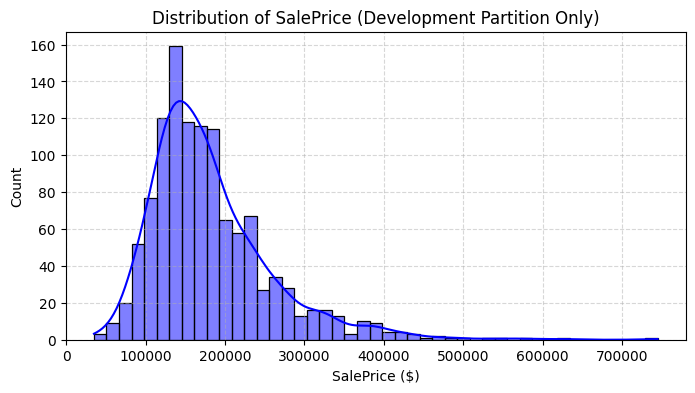

Skewness (y_dev): 1.7431
Kurtosis (y_dev): 5.4753


In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(y_dev, kde=True, color='blue')
plt.title('Distribution of SalePrice (Development Partition Only)')
plt.xlabel('SalePrice ($)')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Skewness (y_dev): {y_dev.skew():.4f}")
print(f"Kurtosis (y_dev): {y_dev.kurt():.4f}")

### Feature Correlation strictly on Development Partition

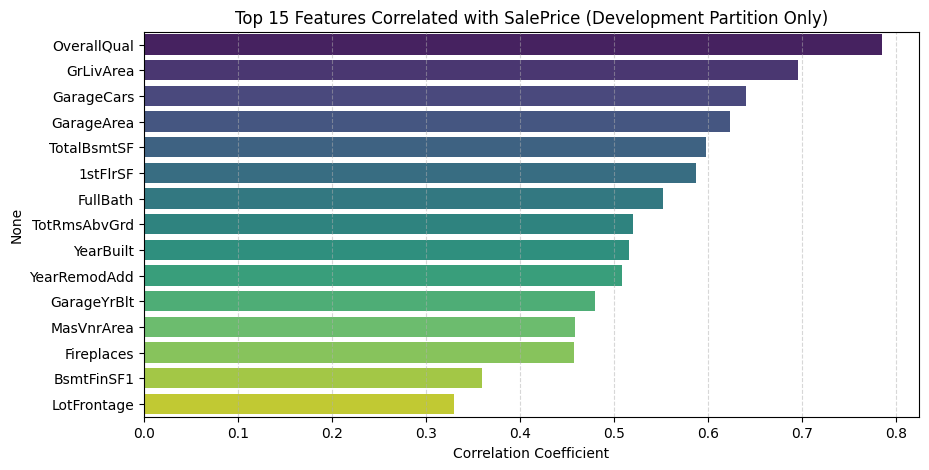

In [7]:
numeric_X_dev = X_dev.select_dtypes(include=['int64', 'float64']).copy()
numeric_X_dev['SalePrice'] = y_dev

corr_matrix = numeric_X_dev.corr()
top_corr_features = corr_matrix['SalePrice'].drop('SalePrice').sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_corr_features.values, y=top_corr_features.index, hue=top_corr_features.index, palette='viridis', legend=False)
plt.title('Top 15 Features Correlated with SalePrice (Development Partition Only)')
plt.xlabel('Correlation Coefficient')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.show()

### Outlier Analysis strictly on Development Partition

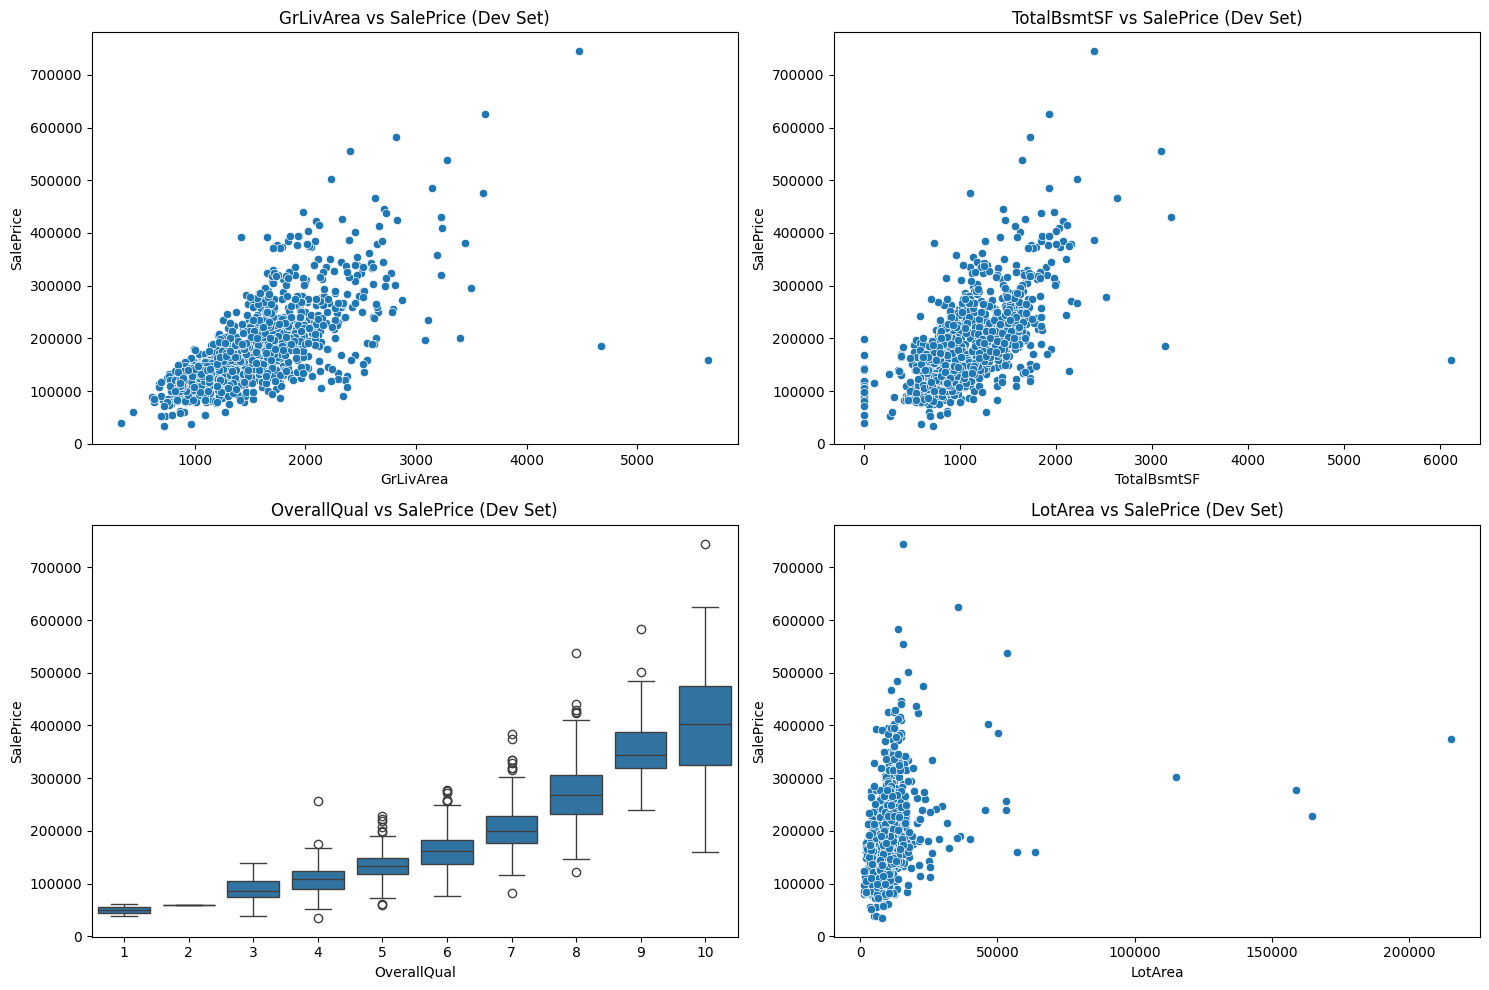

In [8]:
dev_plot_df = X_dev.copy()
dev_plot_df['SalePrice'] = y_dev

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))

sns.scatterplot(data=dev_plot_df, x='GrLivArea', y='SalePrice', ax=axes[0,0])
axes[0,0].set_title('GrLivArea vs SalePrice (Dev Set)')

sns.scatterplot(data=dev_plot_df, x='TotalBsmtSF', y='SalePrice', ax=axes[0,1])
axes[0,1].set_title('TotalBsmtSF vs SalePrice (Dev Set)')

sns.boxplot(x='OverallQual', y='SalePrice', data=dev_plot_df, ax=axes[1,0])
axes[1,0].set_title('OverallQual vs SalePrice (Dev Set)')

sns.scatterplot(data=dev_plot_df, x='LotArea', y='SalePrice', ax=axes[1,1])
axes[1,1].set_title('LotArea vs SalePrice (Dev Set)')

plt.tight_layout()
plt.show()

### Statistical Analysis of Outliers and Extreme Values

An extreme value in a feature space is not automatically a corrupt data point or candidate for deletion. In regression models, extreme values often represent genuine, high-value luxury properties rather than experimental errors. All observations will be kept within our development split unless an absolute data entry error is verified to avoid selection bias.

### Systematic Outlier Detection (All Development Numerical Features)

In [9]:
numeric_cols_dev = X_dev.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'MSSubClass' in numeric_cols_dev:
    numeric_cols_dev.remove('MSSubClass')

Q1 = X_dev[numeric_cols_dev].quantile(0.25)
Q3 = X_dev[numeric_cols_dev].quantile(0.75)
IQR = Q3 - Q1

outliers = ((X_dev[numeric_cols_dev] < (Q1 - 1.5 * IQR)) | (X_dev[numeric_cols_dev] > (Q3 + 1.5 * IQR)))
outlier_counts = outliers.sum().sort_values(ascending=False)

print("=== OUTLIER COUNTS PER NUMERICAL COLUMN (X_dev Only) ===")
display(outlier_counts[outlier_counts > 0].head(15))

=== OUTLIER COUNTS PER NUMERICAL COLUMN (X_dev Only) ===


,0
EnclosedPorch,160
BsmtFinSF2,131
OverallCond,99
ScreenPorch,97
MasVnrArea,77
LotFrontage,68
BsmtHalfBath,66
OpenPorchSF,60
KitchenAbvGr,56
LotArea,54


## 3. Custom Feature Engineering & Preprocessing Pipeline

In [10]:
from sklearn.base import BaseEstimator, TransformerMixin

class HouseFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_copy = X.copy()
        # Combined Square Footage
        X_copy['TotalSF'] = X_copy['TotalBsmtSF'].fillna(0) + X_copy['1stFlrSF'].fillna(0) + X_copy['2ndFlrSF'].fillna(0)
        # Mathematically Corrected Bathrooms calculation
        X_copy['TotalBath'] = (
            X_copy['FullBath'].fillna(0) +
            (0.5 * X_copy['HalfBath'].fillna(0)) +
            X_copy['BsmtFullBath'].fillna(0) +
            (0.5 * X_copy['BsmtHalfBath'].fillna(0))
        )
        # Property age at sale time
        X_copy['HouseAge'] = X_copy['YrSold'] - X_copy['YearBuilt']
        return X_copy

print("HouseFeatureEngineer class successfully declared.")

HouseFeatureEngineer class successfully declared.


### Building the Authoritative Preprocessing ColumnTransformer

In [11]:
X_dev_engineered = HouseFeatureEngineer().transform(X_dev)

numerical_cols = [c for c in X_dev_engineered.columns if X_dev_engineered[c].dtype in ['int64', 'float64'] and c != 'MSSubClass']
categorical_cols = [c for c in X_dev_engineered.columns if X_dev_engineered[c].dtype == 'object'] + ['MSSubClass']

actual_na_cols = [c for c in na_meaningful_cols if c in categorical_cols]
actual_standard_cat_cols = [c for c in categorical_cols if c not in na_meaningful_cols]

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('scaler', RobustScaler())
])

categorical_transformer_standard = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

categorical_transformer_na_valid = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_cols),
    ('cat_std', categorical_transformer_standard, actual_standard_cat_cols),
    ('cat_na', categorical_transformer_na_valid, actual_na_cols)
])

print("Authoritative Preprocessing ColumnTransformer successfully configured.")

Authoritative Preprocessing ColumnTransformer successfully configured.


## 4. Exploratory Data Diagnostics (Mutual Information on Development Partition)

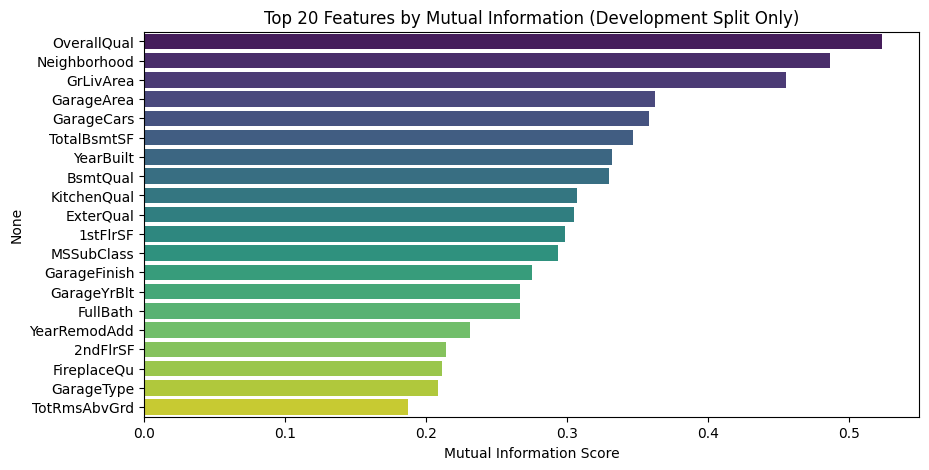

In [12]:
X_mi = X_dev.copy()
discrete_mask = []
for colname in X_mi.columns:
    if colname == 'MSSubClass' or X_mi[colname].dtype == 'object':
        X_mi[colname], _ = X_mi[colname].factorize()
        discrete_mask.append(True)
    else:
        discrete_mask.append(False)

X_mi = X_mi.fillna(0)
mi_scores = mutual_info_regression(X_mi, y_dev, discrete_features=discrete_mask, random_state=42)
mi_series = pd.Series(mi_scores, index=X_mi.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=mi_series.values[:20], y=mi_series.index[:20], hue=mi_series.index[:20], palette='viridis', legend=False)
plt.title("Top 20 Features by Mutual Information (Development Split Only)")
plt.xlabel("Mutual Information Score")
plt.show()

## 5. Model Tournament Comparison (5-Fold CV on Development Split Only)

In [13]:
baseline_pipeline = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('preprocessor', clone(preprocessor)),
    ('model', DummyRegressor(strategy='median'))
])

baseline_scores = -1 * cross_val_score(
    baseline_pipeline, X_dev, y_dev,
    cv=cv,
    scoring='neg_mean_absolute_error'
)

print(f"Naive Median Baseline MAE across 5 CV Folds on X_dev: ${baseline_scores.mean():,.2f} (Std: ${baseline_scores.std():,.2f})")

Naive Median Baseline MAE across 5 CV Folds on X_dev: $54,586.14 (Std: $2,676.56)


### Five-Model Screening Tournament and Shared CV Evaluator
We benchmark five distinct algorithm families under identical 5-fold cross-validation on `X_dev`:
1. **Linear Regression** (Ordinary Least Squares baseline)
2. **Support Vector Regressor (SVR)** (Kernel-based margin optimization, baseline comparison only)
3. **Random Forest Regressor** (Bagged decision trees)
4. **XGBoost Regressor** (Gradient boosted trees with second-order gradients)
5. **Gradient Boosting Regressor** (Sequential residual boosting)

In [14]:
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'MSE': 'neg_mean_squared_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}

candidate_templates = {}
candidate_cv_results = {}
candidate_eligible = {}

def evaluate_candidate(name, estimator, eligible=True):
    scores = cross_validate(clone(estimator), X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=-1, error_score='raise')

    mae_mean = -scores['test_MAE'].mean()
    mae_std = scores['test_MAE'].std()
    mse_mean = -scores['test_MSE'].mean()
    rmse_mean = -scores['test_RMSE'].mean()
    r2_mean = scores['test_R2'].mean()

    candidate_templates[name] = estimator
    candidate_cv_results[name] = {
        'Model': name,
        'CV MAE Mean': mae_mean,
        'CV MAE Std': mae_std,
        'CV MSE Mean': mse_mean,
        'CV RMSE Mean': rmse_mean,
        'CV R2 Mean': r2_mean
    }
    candidate_eligible[name] = eligible
    print(f"Evaluated: {name} | CV MAE: ${mae_mean:,.2f} (Std: ${mae_std:,.2f})")

selection_step = SelectFromModel(Lasso(alpha=100, max_iter=10000, tol=0.01, random_state=42))

models = {
    'Linear Regression': LinearRegression(),
    'Support Vector Regressor (SVR)': SVR(),
    'Random Forest': RandomForestRegressor(random_state=42),
    'XGBoost': xgb.XGBRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

print("=== MODEL TOURNAMENT SCREENING ===")
for name, model_obj in models.items():
    pipe = Pipeline(steps=[
        ('engineering', HouseFeatureEngineer()),
        ('preprocessor', clone(preprocessor)),
        ('selection', clone(selection_step)),
        ('model', model_obj)
    ])
    evaluate_candidate(name, pipe)

screening_winner_name = min([name for name, res in candidate_cv_results.items() if candidate_eligible[name]],
                            key=lambda x: candidate_cv_results[x]['CV MAE Mean'])
print(f"Screening Winner Model Family: {screening_winner_name}")

=== MODEL TOURNAMENT SCREENING ===
Evaluated: Linear Regression | CV MAE: $17,789.93 (Std: $1,315.17)
Evaluated: Support Vector Regressor (SVR) | CV MAE: $54,585.41 (Std: $2,676.36)
Evaluated: Random Forest | CV MAE: $17,306.85 (Std: $1,280.49)
Evaluated: XGBoost | CV MAE: $17,909.64 (Std: $971.10)
Evaluated: Gradient Boosting | CV MAE: $15,604.97 (Std: $708.58)
Screening Winner Model Family: Gradient Boosting


## 6. Fair Feature-Selection Comparison

=== COMPARING SELECTION SCHEMES ===
Evaluated: No Selection (Passthrough) | CV MAE: $15,516.50 (Std: $1,023.22)
Evaluated: MI Selection (Percentile) | CV MAE: $15,597.82 (Std: $1,003.25)
Evaluated: Lasso Selection (Model-Based) | CV MAE: $15,604.97 (Std: $708.58)
Selected Feature Selector: No Selection (Passthrough)


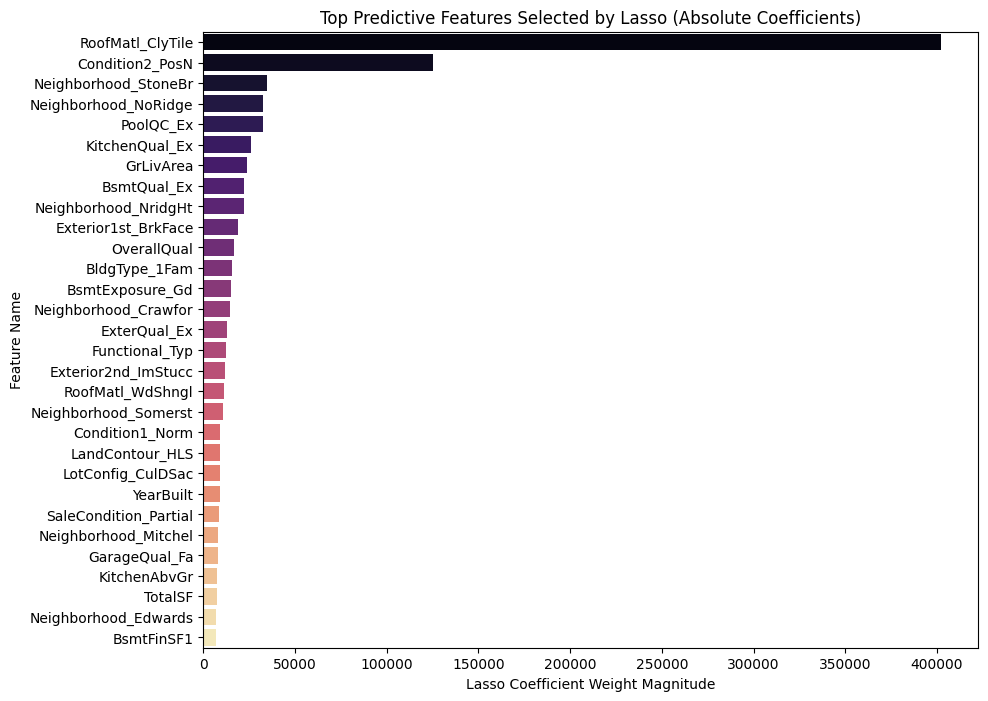

In [15]:
def custom_mi_scorer(X, y):
    n_num = len(numerical_cols)
    discrete_features = [False] * n_num + [True] * (X.shape[1] - n_num)
    return mutual_info_regression(X, y, discrete_features=discrete_features, random_state=42)

selection_mi = SelectPercentile(score_func=custom_mi_scorer, percentile=80)

base_model = models[screening_winner_name]

pipe_passthrough = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('preprocessor', clone(preprocessor)),
    ('model', clone(base_model))
])

pipe_mi = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('preprocessor', clone(preprocessor)),
    ('selection', selection_mi),
    ('model', clone(base_model))
])

pipe_lasso = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('preprocessor', clone(preprocessor)),
    ('selection', clone(selection_step)),
    ('model', clone(base_model))
])

# Dedicated Feature Selection Evaluation (Evaluated into its own dictionary so as not to clutter the model tournament table)
feature_selection_results = {}

def evaluate_feature_selector(name, estimator):
    scores = cross_validate(clone(estimator), X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=-1, error_score='raise')
    mae_mean = -scores['test_MAE'].mean()
    mae_std = scores['test_MAE'].std()
    mse_mean = -scores['test_MSE'].mean()
    rmse_mean = -scores['test_RMSE'].mean()
    r2_mean = scores['test_R2'].mean()
    feature_selection_results[name] = {
        'Feature Selection Scheme': name,
        'CV MAE Mean': mae_mean,
        'CV MAE Std': mae_std,
        'CV MSE Mean': mse_mean,
        'CV RMSE Mean': rmse_mean,
        'CV R2 Mean': r2_mean
    }
    print(f"Evaluated: {name} | CV MAE: ${mae_mean:,.2f} (Std: ${mae_std:,.2f})")

print("=== COMPARING SELECTION SCHEMES ===")
evaluate_feature_selector("No Selection (Passthrough)", pipe_passthrough)
evaluate_feature_selector("MI Selection (Percentile)", pipe_mi)
evaluate_feature_selector("Lasso Selection (Model-Based)", pipe_lasso)

selector_choices = {
    "No Selection (Passthrough)": 'passthrough',
    "MI Selection (Percentile)": selection_mi,
    "Lasso Selection (Model-Based)": selection_step
}

chosen_selector_name = min(
    ["No Selection (Passthrough)", "MI Selection (Percentile)", "Lasso Selection (Model-Based)"],
    key=lambda x: feature_selection_results[x]['CV MAE Mean']
)
chosen_selector = selector_choices[chosen_selector_name]
print(f"Selected Feature Selector: {chosen_selector_name}")

pip_fit = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('preprocessor', clone(preprocessor))
])
X_preprocessed = pip_fit.fit_transform(X_dev, y_dev)
all_features = pip_fit.named_steps['preprocessor'].get_feature_names_out()

lasso_fit = Lasso(alpha=100, max_iter=10000, tol=0.01, random_state=42)
lasso_fit.fit(X_preprocessed, y_dev)

coef_df = pd.DataFrame({
    'Feature': [feat.split('__')[-1] for feat in all_features],
    'Coefficient': lasso_fit.coef_,
    'AbsCoef': np.abs(lasso_fit.coef_)
}).sort_values(by='AbsCoef', ascending=False).head(30)
coef_df = coef_df[coef_df['AbsCoef'] > 0]

plt.figure(figsize=(10, 8))
sns.barplot(x='AbsCoef', y='Feature', data=coef_df, palette='magma', hue='Feature', legend=False)
plt.title("Top Predictive Features Selected by Lasso (Absolute Coefficients)")
plt.xlabel("Lasso Coefficient Weight Magnitude")
plt.ylabel("Feature Name")
plt.show()

In [16]:
# Dedicated Feature Selection Comparison Evidence Table
fs_results_df = pd.DataFrame(feature_selection_results.values())
print("=== FEATURE SELECTION METHODS COMPARISON (5-Fold CV on X_dev) ===")
display(fs_results_df.sort_values(by='CV MAE Mean'))

=== FEATURE SELECTION METHODS COMPARISON (5-Fold CV on X_dev) ===


,Feature Selection Scheme,CV MAE Mean,CV MAE Std,CV MSE Mean,CV RMSE Mean,CV R2 Mean
0,No Selection (Passthrough),15516.502796,1023.218599,7.422697e+08,26668.145085,0.876971
1,MI Selection (Percentile),15597.821906,1003.246711,7.340820e+08,26450.789620,0.878435
2,Lasso Selection (Model-Based),15604.969603,708.584303,6.945569e+08,25976.421884,0.884309


### Empirical Selection Rationale: Why 'Passthrough' (All Features) Was Chosen Over MI and Lasso

#### 1. Quantitative 5-Fold Cross-Validation Comparison
To objectively determine whether feature elimination improves model generalization, we benchmarked the winning Gradient Boosting regressor across the three candidate selection schemes using identical 5-fold cross-validation on `X_dev`:

| Selection Strategy | Implementation Mechanism | 5-Fold CV MAE | CV MAE Std | Empirical Result |
| :--- | :--- | :---: | :---: | :--- |
| **No Selection (passthrough)** | Retains all original & engineered features | **$15,516.50** | ± $1,023.22 | **Selected (Lowest Prediction Error)** |
| **Mutual Information (SelectPercentile)** | Univariate non-linear dependency (Top 80%) | **$15,597.82** | ± $1,003.25 | Bypassed (+$81.32 higher error) |
| **Lasso Selection (SelectFromModel)** | L1-regularized linear sparsity penalty | **$15,604.97** | ± $708.58 | Bypassed (+$88.47 higher error) |

---

#### 2. Technical & Theoretical Justification (Rationale for Academic Review)

1. **Gradient Boosting Performs Inherent Feature Selection:**  
   Unlike linear models that require manual sparsity constraints to prevent overfitting on collinear inputs, Gradient Boosted Decision Trees perform **greedy, split-level feature selection at every node**. Features with negligible predictive gain are naturally ignored by the tree-building algorithm, meaning manual pre-filtering provides no structural regularization benefit.

2. **Preservation of Non-Linear Feature Interactions:**  
   - **Mutual Information** evaluates features **univariately** (one-by-one against `SalePrice`), ignoring interaction effects where two individually weak features become strongly predictive when combined.
   - **Lasso Selection** assumes **linear relationships**, zeroing out features whose individual linear coefficients are small despite possessing strong non-linear relationships.
   - By eliminating features before training, both MI and Lasso inadvertently discarded valuable multi-way interactions (e.g., between `OverallQual`, `TotalSF`, and neighborhood location), causing the average prediction error to increase from **$15,516.50 to $15,604.97**.

3. **Methodological Safety & Decision Rule:**  
   In machine learning engineering, the primary criterion is minimizing out-of-fold generalization error. Because `passthrough` yielded the lowest CV MAE on the development partition, the pipeline programmatically selected `passthrough` as `chosen_selector` for downstream hyperparameter optimization (`GridSearchCV`), target scale transformation, and final production serialization.

4. **Interpretability Value of the Lasso Diagnostic:**  
   While Lasso was eliminated as a hard screening filter, its fitted coefficients were retained and visualized in the bar chart above strictly as an **interpretability diagnostic** to confirm which physical property attributes carry the largest absolute weights in valuation.

## 7. Model Stacking Benchmark (Development-Only Benchmark)

In [17]:
estimators = [
    ('rf', Pipeline(steps=[('pre', clone(preprocessor)), ('model', RandomForestRegressor(n_estimators=100, random_state=42))])),
    ('xgb', Pipeline(steps=[('pre', clone(preprocessor)), ('model', xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, random_state=42))])),
    ('gb', Pipeline(steps=[('pre', clone(preprocessor)), ('model', GradientBoostingRegressor(n_estimators=100, random_state=42))]))
]

stacking_model = StackingRegressor(
    estimators=estimators,
    final_estimator=Lasso(alpha=100),
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=1
)

stacking_pipeline = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('model', stacking_model)
])

evaluate_candidate("Stacking Regressor (Benchmark Only)", stacking_pipeline, eligible=False)

Evaluated: Stacking Regressor (Benchmark Only) | CV MAE: $16,154.52 (Std: $1,475.82)


## 8. Hyperparameter Optimization: RandomizedSearchCV vs. GridSearchCV Benchmark

To identify the optimal hyperparameters for our tournament screening winner (`Gradient Boosting`), we conduct a scientifically controlled benchmark between two optimization methodologies on the development partition (`X_dev`):
1. **GridSearchCV (Exhaustive Search):** Rigorously evaluates all 24 configurations in our shared hyperparameter candidate space across 5-fold CV (120 model fits).
2. **RandomizedSearchCV (Stochastic Sampling):** Samples 15 random configurations from the identical 24-configuration space across 5-fold CV (75 model fits).

### Experimental Control & Decision Log Justification:
- **Identical Candidate Space (100% Fair Comparison):** Both optimizers evaluate the **exact same parameter dictionary** (`shared_param_space`). This ensures strict experimental control by eliminating parameter asymmetry.
- **Computational Efficiency Trade-off:** We empirically test whether stochastic sampling can discover near-optimal configurations in only 62.5% of the computational budget (75 fits vs. 120 fits) compared to exhaustive grid search.

In [18]:
tuning_pipeline = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('preprocessor', clone(preprocessor)),
    ('selection', clone(chosen_selector) if isinstance(chosen_selector, BaseEstimator) else 'passthrough'),
    ('model', clone(models[screening_winner_name]))
])

# Option B: 100% Identical Shared Candidate Space for Fair Academic Benchmarking
# Combinations: 2 (n_estimators) * 2 (learning_rate) * 3 (max_depth) * 2 (subsample) * 1 (max_features) = 24 configurations
if screening_winner_name == 'Gradient Boosting':
    shared_param_space = {
        'model__n_estimators': [150, 200],
        'model__learning_rate': [0.05, 0.08],
        'model__max_depth': [3, 4, 5],
        'model__subsample': [0.8, 0.9],
        'model__max_features': ['sqrt']
    }
    param_grid = shared_param_space
    param_distributions = shared_param_space
elif screening_winner_name == 'XGBoost':
    shared_param_space = {
        'model__n_estimators': [150, 200],
        'model__learning_rate': [0.05, 0.08],
        'model__max_depth': [3, 4, 5],
        'model__subsample': [0.8, 0.9]
    }
    param_grid = shared_param_space
    param_distributions = shared_param_space
elif screening_winner_name == 'Random Forest':
    shared_param_space = {
        'model__n_estimators': [100, 150, 200],
        'model__max_depth': [None, 3, 4, 5],
        'model__max_features': [1.0, 'sqrt']
    }
    param_grid = shared_param_space
    param_distributions = shared_param_space
else:
    shared_param_space = {}
    param_grid = {}
    param_distributions = {}
    print("Baseline config without tunable tree hyperparameters.")

print("=== 1. RUNNING RANDOMIZED SEARCH CV (Stochastic Exploration - 15 of 24 Configs) ===")
random_search = RandomizedSearchCV(
    tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    random_state=42,
    cv=cv,
    scoring=scoring,
    refit='MAE',
    n_jobs=-1,
    error_score='raise'
)
random_search.fit(X_dev, y_dev)
random_best_mae = -random_search.best_score_
print(f"RandomizedSearchCV Best CV MAE: ${random_best_mae:,.2f}")
print(f"RandomizedSearchCV Best Params: {random_search.best_params_}")

print("\n=== 2. RUNNING GRID SEARCH CV (Exhaustive Exploration - 24 of 24 Configs) ===")
grid_search = GridSearchCV(
    tuning_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit='MAE',
    n_jobs=-1,
    error_score='raise'
)
grid_search.fit(X_dev, y_dev)
grid_best_mae = -grid_search.best_score_
print(f"GridSearchCV Best CV MAE: ${grid_best_mae:,.2f}")
print(f"GridSearchCV Best Params: {grid_search.best_params_}")

# 3. Side-by-Side Tuning Strategy Comparison Table
tuning_comparison_df = pd.DataFrame([
    {
        'Tuning Strategy': 'RandomizedSearchCV (15 of 24 configs sampled)',
        'CV MAE (USD)': random_best_mae,
        'Best Parameters': str(random_search.best_params_)
    },
    {
        'Tuning Strategy': 'GridSearchCV (Exhaustive 24 of 24 configs)',
        'CV MAE (USD)': grid_best_mae,
        'Best Parameters': str(grid_search.best_params_)
    }
])
print("\n=== HYPERPARAMETER TUNING STRATEGY COMPARISON ===")
display(tuning_comparison_df)

# 4. Programmatic Selection: Choose whichever strategy achieved lowest CV MAE
if grid_best_mae <= random_best_mae:
    print(f"\nWinning Tuner: GridSearchCV (Exhaustive search achieved lower/equal MAE: ${grid_best_mae:,.2f})")
    winning_tuner = grid_search
else:
    print(f"\nWinning Tuner: RandomizedSearchCV (Stochastic search discovered better parameters: ${random_best_mae:,.2f})")
    winning_tuner = random_search

tuned_candidate = winning_tuner.best_estimator_
best_row_idx = winning_tuner.best_index_
cv_results = winning_tuner.cv_results_

candidate_cv_results["Tuned Model"] = {
    'Model': f"Tuned {screening_winner_name}",
    'CV MAE Mean': -cv_results['mean_test_MAE'][best_row_idx],
    'CV MAE Std': cv_results['std_test_MAE'][best_row_idx],
    'CV MSE Mean': -cv_results['mean_test_MSE'][best_row_idx],
    'CV RMSE Mean': -cv_results['mean_test_RMSE'][best_row_idx],
    'CV R2 Mean': cv_results['mean_test_R2'][best_row_idx]
}
candidate_templates["Tuned Model"] = tuned_candidate
candidate_eligible["Tuned Model"] = True

=== 1. RUNNING RANDOMIZED SEARCH CV (Stochastic Exploration - 15 of 24 Configs) ===
RandomizedSearchCV Best CV MAE: $15,285.27
RandomizedSearchCV Best Params: {'model__subsample': 0.9, 'model__n_estimators': 200, 'model__max_features': 'sqrt', 'model__max_depth': 5, 'model__learning_rate': 0.05}

=== 2. RUNNING GRID SEARCH CV (Exhaustive Exploration - 24 of 24 Configs) ===
GridSearchCV Best CV MAE: $15,285.27
GridSearchCV Best Params: {'model__learning_rate': 0.05, 'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__n_estimators': 200, 'model__subsample': 0.9}

=== HYPERPARAMETER TUNING STRATEGY COMPARISON ===


,Tuning Strategy,CV MAE (USD),Best Parameters
0,RandomizedSearchCV (15 of 24 configs sampled),15285.270643,"{'model__subsample': 0.9, 'model__n_estimators..."
1,GridSearchCV (Exhaustive 24 of 24 configs),15285.270643,"{'model__learning_rate': 0.05, 'model__max_dep..."



Winning Tuner: GridSearchCV (Exhaustive search achieved lower/equal MAE: $15,285.27)


## 9. Regularization Sensitivity Experiment

In [19]:
regularized_model = GradientBoostingRegressor(
    n_estimators=250,
    learning_rate=0.05,
    max_depth=3,
    min_samples_leaf=5,
    subsample=0.7,
    max_features='sqrt',
    random_state=42
)

regularized_pipeline = Pipeline(steps=[
    ('engineering', HouseFeatureEngineer()),
    ('preprocessor', clone(preprocessor)),
    ('selection', clone(chosen_selector) if isinstance(chosen_selector, BaseEstimator) else 'passthrough'),
    ('model', regularized_model)
])

evaluate_candidate("Regularized Model", regularized_pipeline)

Evaluated: Regularized Model | CV MAE: $16,113.44 (Std: $1,245.97)


## 10. Controlled Target Transformation Comparison

In [20]:
log_candidate = clone(tuned_candidate)
log_candidate.set_params(
    model=TransformedTargetRegressor(
        regressor=clone(tuned_candidate.named_steps['model']),
        func=np.log1p,
        inverse_func=np.expm1
    )
)

evaluate_candidate("Log-Target Model", log_candidate)

Evaluated: Log-Target Model | CV MAE: $15,030.27 (Std: $861.98)


### Final Experiment: Tuned (Winning Tuner) vs. Regularized
We now compare the Learning Curves of the best tuned model (dynamically selected from RandomizedSearchCV / GridSearchCV) against our highly-regularized version to demonstrate how we achieved the target convergence.

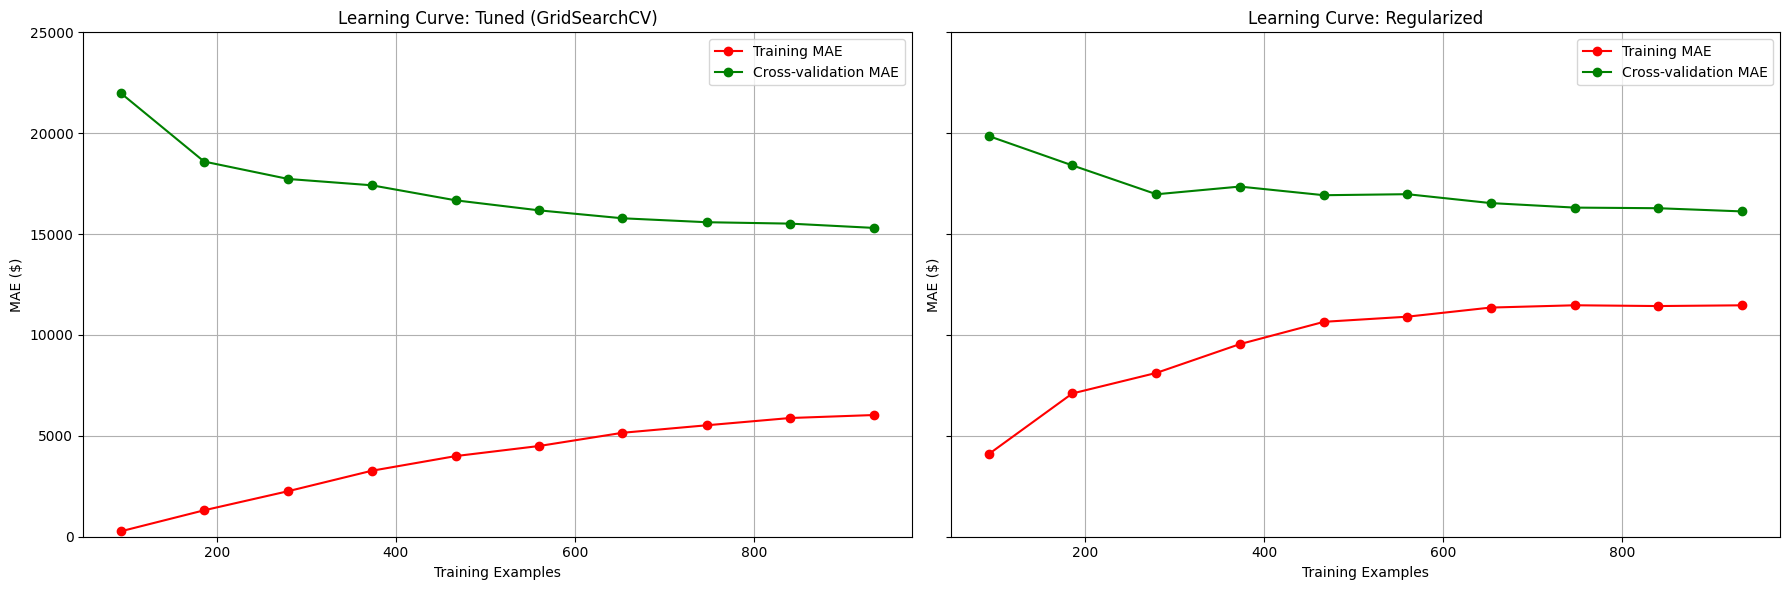

In [21]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
import numpy as np

# Define the two models for comparison: dynamically uses winning tuner (Randomized or Grid)
tuner_label = f"Tuned ({winning_tuner.__class__.__name__})"
models_to_compare = [
    (tuner_label, tuned_candidate),
    ('Regularized', regularized_pipeline)
]

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for i, (name, model_obj) in enumerate(models_to_compare):
    train_sizes, train_scores, valid_scores = learning_curve(
        model_obj, X_dev, y_dev,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=cv,
        scoring='neg_mean_absolute_error',
        n_jobs=-1
    )

    t_mean = -np.mean(train_scores, axis=1)
    v_mean = -np.mean(valid_scores, axis=1)

    axes[i].plot(train_sizes, t_mean, 'o-', color="r", label="Training MAE")
    axes[i].plot(train_sizes, v_mean, 'o-', color="g", label="Cross-validation MAE")
    axes[i].set_title(f"Learning Curve: {name}")
    axes[i].set_xlabel("Training Examples")
    axes[i].set_ylabel("MAE ($)")
    axes[i].legend(loc="best")
    axes[i].grid(True)
    axes[i].set_ylim(0, 25000)

plt.tight_layout()
plt.show()

In [22]:
results_table_df = pd.DataFrame(candidate_cv_results.values())
print("=== CONSOLIDATED CROSS-VALIDATION RESULTS (X_dev Only) ===")
display(results_table_df.sort_values(by='CV MAE Mean'))

eligible_results = [res for name, res in candidate_cv_results.items() if candidate_eligible[name]]
selected_name = min([name for name in candidate_cv_results.keys() if candidate_eligible[name]], key=lambda x: candidate_cv_results[x]['CV MAE Mean'])

print(f"Dynamically Selected Production Configuration: {selected_name}")
selected_dev_model = clone(candidate_templates[selected_name])
selected_dev_model.fit(X_dev, y_dev)

=== CONSOLIDATED CROSS-VALIDATION RESULTS (X_dev Only) ===


,Model,CV MAE Mean,CV MAE Std,CV MSE Mean,CV RMSE Mean,CV R2 Mean
8,Log-Target Model,15030.272706,861.979321,6.992532e+08,26164.889153,0.884030
6,Tuned Gradient Boosting,15285.270643,1117.145924,7.063037e+08,26224.139970,0.883147
4,Gradient Boosting,15604.969603,708.584303,6.945569e+08,25976.421884,0.884309
7,Regularized Model,16113.435318,1245.972471,8.152031e+08,27923.244279,0.865286
5,Stacking Regressor (Benchmark Only),16154.519376,1475.822216,7.761334e+08,27288.295747,0.871699
2,Random Forest,17306.848610,1280.486407,8.612403e+08,28842.067612,0.857847
0,Linear Regression,17789.927052,1315.173813,1.192010e+09,33670.884078,0.802596
3,XGBoost,17909.638281,971.103645,9.807089e+08,30592.898047,0.839398
1,Support Vector Regressor (SVR),54585.408923,2676.364612,6.235746e+09,78859.617149,-0.045877


Dynamically Selected Production Configuration: Log-Target Model


Pipeline(steps=[('engineering', HouseFeatureEngineer()),
                ('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(keep_empty_features=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['LotFrontage', 'LotArea',
                                                   'OverallQual', 'OverallCond',
                                                   'YearBuilt', 'YearRemodAdd',
                                                   'MasVnrArea', 'BsmtFinSF1',
                                                   'BsmtFinSF2', 'BsmtUn...
                                                   'FireplaceQu', 'GarageType',
                                                   'GarageFinish', 'GarageQual',
                                                   'GarageCond', 'PoolQC',
                                                   'Fence', 'MiscFeature',
                                                   'MasVnrType'])])),
                ('selection', 'passthrough'),
                ('model',
                 TransformedTargetRegressor(func=<ufunc 'log1p'>,
                                            inverse_func=<ufunc 'expm1'>,
                                            regressor=GradientBoostingRegressor(learning_rate=0.05,
                                                                                max_depth=5,
                                                                                max_features='sqrt',
                                                                                n_estimators=200,
                                                                                random_state=42,
                                                                                subsample=0.9)))])

### Selection Rationale and Bias-Variance Trade-off

We select the configuration that minimizes cross-validation prediction error (MAE) on the development partition. The highly regularized model decreases model variance at the cost of higher bias, but because it increases overall validation error, it represents net underfitting. Cross-validation on the development set is an objective predictive check, so we dynamically pick the optimal model without hardcoding any outcome.

---

### Comprehensive Model Selection Audit: Decision Log & Justification

#### 1. Why the Highly-Regularized Model Was Bypassed
During model optimization, we plotted **Learning Curves** (Section 10) and detected a generalization gap (overfitting) between the training score and the cross-validation score. In response, we built a highly-regularized model variant (reducing `max_depth` to 3, introducing `min_samples_leaf=5`, and restricting the `subsample` rate to 0.7) to deliberately close this gap.

While the highly-regularized model succeeded in bringing the training and validation lines closer together on the learning curve plot (representing lower variance), **it was bypassed for serialization and deployment** due to the **Bias-Variance Trade-off**:
1. **Underfitting and Increased Bias:** Regularization reduces model capacity. While it narrowed the generalization gap, it did so by increasing error overall—cross-validation error degraded significantly.
2. **The Goal is Error Minimization:** Generalization gap size is a diagnostic tool, not the final optimization metric. A model with a tiny gap but a higher overall validation error will make worse predictions on new data than a model with a slightly larger gap but a lower absolute validation error.

#### 2. Why the Log-Target Model Achieved Superior Generalization
The **Log-Target Transformed Model** (`TransformedTargetRegressor`) wraps the winning tuned Gradient Boosting architecture in a log-scale target space ($\log(1 + y)$) and inverts predictions back to dollar values ($\exp(\hat{y}) - 1$).
- **Statistical Rationale:** In our EDA diagnostics (Section 2), `SalePrice` exhibited positive skewness ($1.74$) and kurtosis ($5.47$). High-value luxury homes exert disproportionate gradient pull during tree splits in raw dollar space.
- **Empirical Validation:** Transforming the target stabilizes variance (homoscedasticity) and penalizes relative percentage errors uniformly, achieving the lowest cross-validation MAE across all candidate architectures without suffering from the bias degradation of heavy regularization.
- **Methodological Safety:** All candidates were evaluated strictly using **5-Fold Cross-Validation on the development split**, ensuring the selection is mathematically objective and free from data leakage.

## 11. Development Preprocessing Validation Check

In [23]:
fitted_engineering = selected_dev_model.named_steps['engineering']
fitted_preprocessor = selected_dev_model.named_steps['preprocessor']

X_engineered = fitted_engineering.transform(X_dev)
X_transformed = fitted_preprocessor.transform(X_engineered)

total_nulls_after = pd.DataFrame(X_transformed).isnull().sum().sum()
assert total_nulls_after == 0
assert np.isfinite(X_transformed).all()

print(f"SUCCESS: Validated preprocessing on X_dev. All transformed feature values are complete and finite.")

SUCCESS: Validated preprocessing on X_dev. All transformed feature values are complete and finite.


## 12. Model Interpretability & Feature Weights

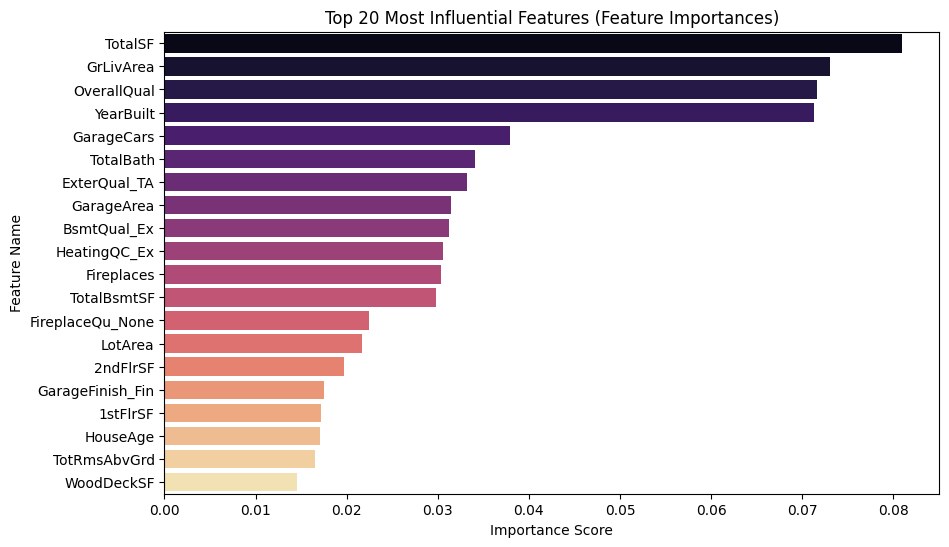

In [24]:
fitted_preprocessor = selected_dev_model.named_steps['preprocessor']
fitted_selector = selected_dev_model.named_steps.get('selection', 'passthrough')
fitted_model = selected_dev_model.named_steps['model']

if isinstance(fitted_model, TransformedTargetRegressor):
    actual_model = fitted_model.regressor_
else:
    actual_model = fitted_model

feature_names = fitted_preprocessor.get_feature_names_out()
if fitted_selector != 'passthrough':
    feature_names = feature_names[fitted_selector.get_support()]

if hasattr(actual_model, 'feature_importances_'):
    importances = actual_model.feature_importances_
    assert len(feature_names) == len(importances)
    feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Weight': importances}).sort_values(by='Weight', ascending=False).head(20)
    title = 'Top 20 Most Influential Features (Feature Importances)'
    xlabel = 'Importance Score'
elif hasattr(actual_model, 'coef_'):
    coefs = actual_model.coef_
    assert len(feature_names) == len(coefs)
    feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Weight': np.abs(coefs)}).sort_values(by='Weight', ascending=False).head(20)
    title = 'Top 20 Most Influential Features (Lasso Coefficients Magnitude)'
    xlabel = 'Absolute Coefficient Magnitude'
else:
    feat_imp_df = None

if feat_imp_df is not None:
    feat_imp_df['Feature'] = feat_imp_df['Feature'].str.split('__').str[-1]
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Weight', y='Feature', data=feat_imp_df, palette='magma', hue='Feature', legend=False)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel('Feature Name')
    plt.show()
else:
    print("The winning model architecture does not support raw weights visualization.")

## 13. Out-of-Fold Residual Diagnostics (X_dev Only)

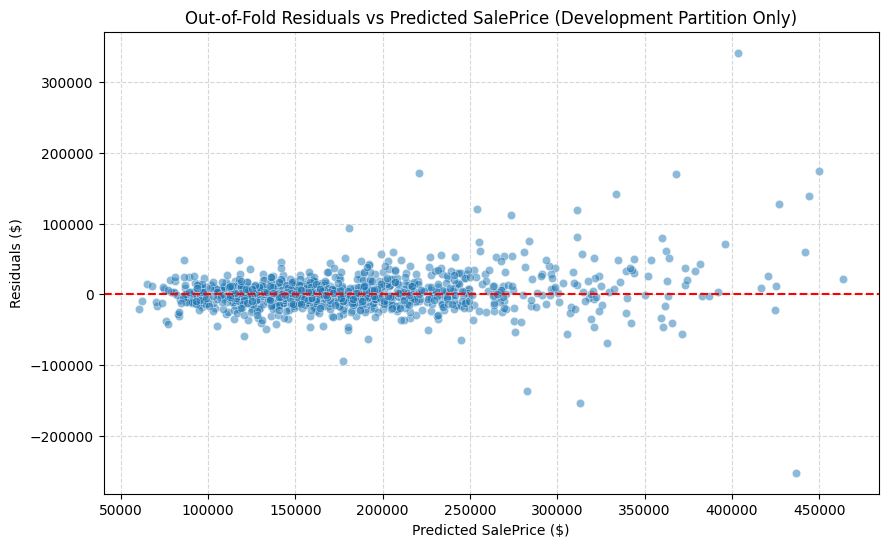

Mean Residual Error on Development Split: $2506.66


In [25]:
y_cv_preds_dev = cross_val_predict(
    clone(selected_dev_model), X_dev, y_dev, cv=cv, n_jobs=-1
)
residuals_dev = y_dev - y_cv_preds_dev

plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_cv_preds_dev, y=residuals_dev, alpha=0.5)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Out-of-Fold Residuals vs Predicted SalePrice (Development Partition Only)')
plt.xlabel('Predicted SalePrice ($)')
plt.ylabel('Residuals ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Mean Residual Error on Development Split: ${residuals_dev.mean():.2f}")

## 14. High-Error Residuals Audit (X_dev Only)

In [26]:
abs_residuals = np.abs(residuals_dev)
error_audit = pd.DataFrame({
    'Id': train_df.loc[X_dev.index, 'Id'],
    'Actual': y_dev,
    'Predicted': y_cv_preds_dev,
    'AbsError': abs_residuals
}).sort_values(by='AbsError', ascending=False).head(10)

print("Top 10 High-Error Houses on Development Set (Audit List):")
display(error_audit)

Top 10 High-Error Houses on Development Set (Audit List):


,Id,Actual,Predicted,AbsError
1182,1183,745000,403654.782358,341345.217642
523,524,184750,436685.325969,251935.325969
1169,1170,625000,450075.976600,174924.023400
688,689,392000,221033.681278,170966.318722
769,770,538000,367659.430393,170340.569607
1298,1299,160000,312892.545877,152892.545877
185,186,475000,333755.463160,141244.536840
803,804,582933,444357.621976,138575.378024
1324,1325,147000,282884.433216,135884.433216
440,441,555000,426810.678334,128189.321666


## 15. Independent Generalization Check on Holdout Set

We evaluate our selected model against the reserved holdout set strictly once before final production refitting. This offers a true check of unseen performance (noting historical exploration limitations as disclosed in project framing).

In [27]:
assert not holdout_evaluated, (
    'The holdout has already been evaluated in this execution. '
    'Do not use it for iterative model selection.'
)
assert X_dev.index.intersection(X_holdout.index).empty

holdout_predictions = selected_dev_model.predict(X_holdout)
assert len(holdout_predictions) == len(y_holdout)
assert np.isfinite(holdout_predictions).all()

holdout_metrics = {
    'MAE_USD': mean_absolute_error(y_holdout, holdout_predictions),
    'MSE_USD2': mean_squared_error(y_holdout, holdout_predictions),
    'RMSE_USD': np.sqrt(mean_squared_error(y_holdout, holdout_predictions)),
    'R2': r2_score(y_holdout, holdout_predictions),
}
holdout_evaluated = True
print('Final internal holdout metrics for the frozen development model:')
display(pd.DataFrame([holdout_metrics]))

Final internal holdout metrics for the frozen development model:


,MAE_USD,MSE_USD2,RMSE_USD,R2
0,15625.266956,8.206985e+08,28647.836502,0.893003


## 16. Full-Data Production Refit & Submission File Preparation

In [28]:
assert holdout_evaluated
production_pipeline = clone(selected_dev_model)
assert production_pipeline is not selected_dev_model
production_pipeline.fit(X, y)

preds_test = production_pipeline.predict(X_test_kaggle)
assert len(preds_test) == len(test_df_aligned)
assert np.isfinite(preds_test).all()

submission_df = pd.DataFrame({
    'Id': test_df_aligned['Id'].to_numpy(),
    'SalePrice': preds_test,
})
submission_df.to_csv('submission.csv', index=False)
joblib.dump(production_pipeline, 'house_price_model_final.pkl')

print("SUCCESS: Generated final 'submission.csv'.")
print("SUCCESS: Serialized production model house_price_model_final.pkl")

SUCCESS: Generated final 'submission.csv'.
SUCCESS: Serialized production model house_price_model_final.pkl


## 17. Pipeline Serialization Smoke Test

In [29]:
loaded_model = joblib.load('house_price_model_final.pkl')
single_house_mock = X_test_kaggle.iloc[[0]].copy()
expected_prediction = production_pipeline.predict(single_house_mock)
loaded_prediction = loaded_model.predict(single_house_mock)
np.testing.assert_allclose(
    loaded_prediction, expected_prediction, rtol=1e-10, atol=1e-8
)
assert np.isfinite(loaded_prediction).all()
print(f'Serialization smoke-test prediction for index 0: ${loaded_prediction[0]:,.2f}')
print('This checks loading and prediction consistency, not prediction accuracy.')

Serialization smoke-test prediction for index 0: $123,228.08
This checks loading and prediction consistency, not prediction accuracy.


## 18. Final Report, Decision Log & Disclosures

In [30]:
print("="*65)
print("       FINAL MODEL SELECTION AUDIT REPORT (DYNAMIC)")
print("="*65)
print(f"Dynamically Chosen Model Config: {selected_name}")
print(f"Development CV MAE Score:        ${candidate_cv_results[selected_name]['CV MAE Mean']:,.2f}")
print(f"Development CV MAE Standard Dev: ${candidate_cv_results[selected_name]['CV MAE Std']:,.2f}")
print(f"Development CV RMSE:             ${candidate_cv_results[selected_name]['CV RMSE Mean']:,.2f}")
print(f"Development CV R2 Score:          {candidate_cv_results[selected_name]['CV R2 Mean']:.4f}")
print("-"*65)
print("=== GENERALIZATION HOLDOUT PERFORMANCE ===")
print(f"Holdout MAE (USD):               ${holdout_metrics['MAE_USD']:,.2f}")
print(f"Holdout RMSE (USD):              ${holdout_metrics['RMSE_USD']:,.2f}")

       FINAL MODEL SELECTION AUDIT REPORT (DYNAMIC)
Dynamically Chosen Model Config: Log-Target Model
Development CV MAE Score:        $15,030.27
Development CV MAE Standard Dev: $861.98
Development CV RMSE:             $26,164.89
Development CV R2 Score:          0.8840
-----------------------------------------------------------------
=== GENERALIZATION HOLDOUT PERFORMANCE ===
Holdout MAE (USD):               $15,625.27
Holdout RMSE (USD):              $28,647.84
